## Setup

In [16]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu118 --upgrade
%pip install kagglehub
%pip install transformers datasets huggingface_hub accelerate

Looking in indexes: https://download.pytorch.org/whl/cu118
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
  Using cached regex-2026.7.19-cp313-cp313-win_amd64.whl.metadata (41 kB)
  Using cached tokenizers-0.22.2-cp39-abi3-win_amd64.whl.metadata (7.4 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
   ---------------------------------------- 0.0/11.7 MB ? eta -:--:--
    --------------------------------------- 0.3/11.7 MB ? eta -:--:--
   ------ --------------------------------- 1.8/11.7 MB 6.0 MB/s eta 0:00:02
   ----------- ---------------------------- 3.4/11.7 MB 6.7 MB/s eta 0:00:02
   ----------- ---------------------------- 3.4/11.7 MB 6.7 MB/s eta 0:00:02
   ---------------------- ----------------- 6.6/11.7 MB 6.9 MB/s eta 0:00:01
   ------------------------------ --------- 8.9/11.7 MB 7.8 MB/s eta 0:00:01
   ---------------------------------------  11.5/11.7 MB 8.

In [23]:
!pip install --force-reinstall pyarrow

  Using cached pyarrow-25.0.1-cp313-cp313-win_amd64.whl.metadata (3.0 kB)
Using cached pyarrow-25.0.1-cp313-cp313-win_amd64.whl (27.9 MB)
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 25.0.1
    Uninstalling pyarrow-25.0.1:
      Successfully uninstalled pyarrow-25.0.1


In [1]:
# import basic packages
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import PIL
import torch


In [2]:
import torch
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))


GPU Available: True
Device Name: NVIDIA GeForce MX250


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\pedro\.cache\kagglehub\datasets\sumn2u\garbage-classification-v2\versions\12


In [4]:
from datasets import load_dataset
dataset = load_dataset(path + "/standardized_384", split="train")

labels = dataset.features["label"].names
print(f"Labels: {labels}")
print(f"Number of images: {dataset.num_rows}")

Resolving data files:   0%|          | 0/12259 [00:00<?, ?it/s]

Labels: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Number of images: 12259


In [5]:
labels_dict = dict(enumerate(labels))
label_name_selection = ['biological', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
label_num_selction  = [k for k, v in labels_dict.items() if v in label_name_selection]
lable_dict_selection = {k: v for k,v in labels_dict.items() if v in label_name_selection}
print(f'Labels selected:\n {label_num_selction}')

Labels selected:
 [1, 2, 4, 5, 6, 7, 9]


In [6]:
#Objective Filtering: Biological, Cardboard, Glass, metal, paper, plastic & trash 
cut_dataset = dataset.filter(lambda x: x["label"] in label_num_selction)
print(f"Number of images: {cut_dataset.num_rows}")

Number of images: 8162


In [7]:
# Load CLIP processor and model
from transformers import CLIPProcessor, CLIPModel

device = 'cuda' if torch.cuda.is_available() else 'cpu'

processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

## Image Exploration

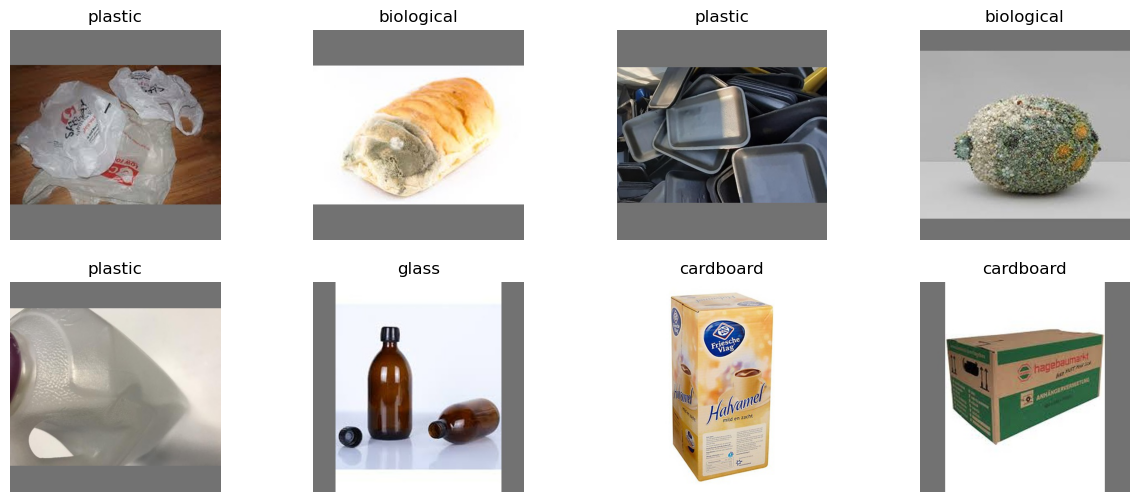

In [8]:
sample = cut_dataset.shuffle(seed=42)[:8]
images = sample["image"]
true_labels = sample["label"]

plt.figure(figsize=(15, 6))
for i, image in enumerate(images):
        plt.subplot(2, int(len(images)/2), i + 1)
        plt.imshow(image)
        plt.title(labels[true_labels[i]]) # adding title to the images for more informative plot
        plt.axis('off') #elimitating axis in plot for a cleaner view 

## Building a Machine Learning Model using CLIP encoder

In [12]:
## function definition to build a pandas dataframe to have a clean visualization of the encoded images
from typing import List
def dataframe_construction(images_list: List, labels: List, processor=processor, batch_size: int = 32) -> pd.DataFrame:
    """
    Encode the images and build a dataframe with the image vector and the label.

    Parameters
    ----------
    images_list : List
        A list of images to be classified
    labels : List
        A list containing the possible classes
    processor
        The processor to be used to transform images (only images) into numerical embeddings
    batch_size : int
        Number of images to process per batch, to avoid memory allocation errors

    Returns
    -------
    encoded_df : dataframe
       A dataframe with the encoded vector and a target class
    """
    all_embeddings = []

    for i in range(0, len(images_list), batch_size):
        batch_images = images_list[i:i + batch_size]

        inputs = processor(images=batch_images, return_tensors='pt', padding=True).to(device)

        with torch.no_grad():
            image_features = model.get_image_features(**inputs)  # extracting embeddings

        all_embeddings.append(image_features.pooler_output.cpu().numpy())

    embeddings = np.concatenate(all_embeddings, axis=0)
    encoded_df = pd.DataFrame(embeddings)
    encoded_df['Class'] = labels

    return encoded_df 

### Testing with higher sample to evaluate PCA & Classifier Behavior

In [10]:
sample_PCA = cut_dataset.shuffle(seed=42)[:8000]
images_PCA = sample_PCA["image"]
true_labels_PCA = sample_PCA["label"]

In [13]:
#data sample separtion for training and testing models
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

embedded_dataframe  = dataframe_construction(images_list=images_PCA, labels = true_labels_PCA)

X = embedded_dataframe.drop(columns='Class')
y = embedded_dataframe['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2 ,stratify=y, random_state = 42)

sc = StandardScaler()
X_train_std = sc.fit_transform(X_train)
X_test_std = sc.transform(X_test)

pca = PCA(n_components = 0.95, svd_solver='full')
Lr_Model = LogisticRegression(random_state=1, solver='lbfgs')

X_train_pca = pca.fit_transform(X_train_std)
X_test_pca = pca.transform(X_test_std)

Lr_Model.fit(X_train_pca, y_train)

print('Model fully fitted')




Model fully fitted


C:\Users\pedro\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


              precision    recall  f1-score   support

  biological       1.00      0.99      1.00       137
   cardboard       0.93      0.95      0.94       277
       glass       0.91      0.94      0.93       342
       metal       0.93      0.91      0.92       182
       paper       0.93      0.92      0.92       261
     plastic       0.92      0.91      0.91       313
       trash       0.85      0.77      0.81        88

    accuracy                           0.93      1600
   macro avg       0.92      0.91      0.92      1600
weighted avg       0.92      0.93      0.92      1600



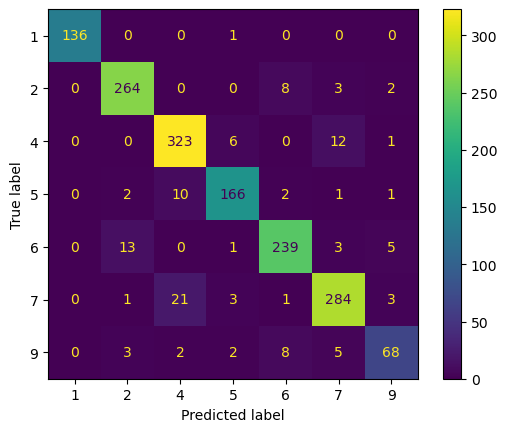

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report

predictions = Lr_Model.predict(X_test_pca)

print(classification_report(y_test, predictions, target_names= lable_dict_selection.values()))

cm = confusion_matrix(y_test, predictions, labels= Lr_Model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=lable_dict_selection.values())
disp.plot()

plt.show()

